In [8]:
import random
import warnings
from pathlib import Path
import zipfile

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PIL import Image
from skimage import color, filters, measure

warnings.filterwarnings("ignore")

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

# Portable dataset path resolution
DEFAULT_PATH = Path(r"C:\Users\george\Desktop\stage1_train")
DATA_DIR = DEFAULT_PATH if DEFAULT_PATH.exists() else Path("./stage1_train")

# Automatically unzip the dataset if found as a zip file
if not DATA_DIR.exists() and Path("/content/stage1_train.zip").exists():
    print("Extracting stage1_train.zip...")
    with zipfile.ZipFile("/content/stage1_train.zip", "r") as zip_ref:
        zip_ref.extractall(DATA_DIR)

assert DATA_DIR.exists(), f"Dataset directory not found at {DATA_DIR}"

plt.rcParams.update({
    "figure.figsize": (12, 5),
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.25,
    "font.size": 10,
})

print(f"Environment ready | Dataset path: {DATA_DIR.resolve()}")

Extracting stage1_train.zip...
Environment ready | Dataset path: /content/stage1_train


In [9]:
def load_image_and_masks(sample_dir: Path):
    """Loads an RGB image and merges its non-overlapping instance masks."""
    img_path = next((sample_dir / "images").glob("*.png"))
    img_rgb = np.array(Image.open(img_path).convert("RGB"))

    mask_paths = sorted((sample_dir / "masks").glob("*.png"))
    h, w = img_rgb.shape[:2]
    instance_mask = np.zeros((h, w), dtype=np.int32)
    overlap_pixels = 0

    for idx, m_path in enumerate(mask_paths, start=1):
        m = np.array(Image.open(m_path)) > 0
        if m.shape != (h, w):
            raise ValueError(f"Shape mismatch in {sample_dir.name}: {m.shape} vs {(h, w)}")
        overlap_pixels += int(np.sum((instance_mask > 0) & m))
        instance_mask = np.where(m, idx, instance_mask)

    return img_rgb, instance_mask, len(mask_paths), overlap_pixels


def classify_background_polarity(gray_float: np.ndarray) -> str:
    """
    Determines whether background is 'dark' or 'bright' using both a 10px border
    sample and Otsu foreground-area majority (nuclei occupy <50% of image area).
    """
    h, w = gray_float.shape
    pad = min(10, h // 4, w // 4)
    border_pixels = np.concatenate([
        gray_float[:pad, :].ravel(),
        gray_float[-pad:, :].ravel(),
        gray_float[:, :pad].ravel(),
        gray_float[:, -pad:].ravel(),
    ])
    border_med = float(np.median(border_pixels))

    thresh = filters.threshold_otsu(gray_float)
    bright_area_ratio = float(np.mean(gray_float > thresh))

    # Bright background if border is bright OR bright pixels dominate (>55% area)
    if border_med > 0.5 or bright_area_ratio > 0.55:
        return "bright"
    return "dark"


def analyze_dataset_integrity(data_dir: Path) -> pd.DataFrame:
    records = []
    sample_dirs = sorted([d for d in data_dir.iterdir() if d.is_dir()])

    for s_dir in sample_dirs:
        img_files = list((s_dir / "images").glob("*.png"))
        mask_files = list((s_dir / "masks").glob("*.png"))

        if not img_files or not mask_files:
            records.append({"image_id": s_dir.name, "valid": False})
            continue

        img_rgb, inst_mask, n_masks, overlaps = load_image_and_masks(s_dir)
        gray = color.rgb2gray(img_rgb)  # Luminance-weighted [0, 1] float
        h, w = gray.shape

        is_color = not (
            np.array_equal(img_rgb[:, :, 0], img_rgb[:, :, 1])
            and np.array_equal(img_rgb[:, :, 1], img_rgb[:, :, 2])
        )
        bg_type = classify_background_polarity(gray)

        props = measure.regionprops(inst_mask)
        areas = [p.area for p in props]

        records.append({
            "image_id": s_dir.name,
            "valid": True,
            "height": h,
            "width": w,
            "resolution": f"{h}x{w}",
            "is_color": is_color,
            "bg_type": bg_type,
            "mean_intensity": float(gray.mean()),
            "std_intensity": float(gray.std()),
            "n_nuclei": n_masks,
            "overlap_pixels": overlaps,
            "fg_ratio": float(np.mean(inst_mask > 0)),
            "median_nucleus_area": float(np.median(areas)) if areas else 0.0,
            "p5_area": float(np.percentile(areas, 5)) if areas else 0.0,
            "p95_area": float(np.percentile(areas, 95)) if areas else 0.0,
        })

    return pd.DataFrame(records)


df = analyze_dataset_integrity(DATA_DIR)
assert df["valid"].all(), "Some samples failed integrity checks!"
assert df["overlap_pixels"].sum() == 0, "Instance mask overlaps detected!"
print(f"Verified {len(df)} samples | 0 missing files | 0 mask overlaps.")

Verified 670 samples | 0 missing files | 0 mask overlaps.


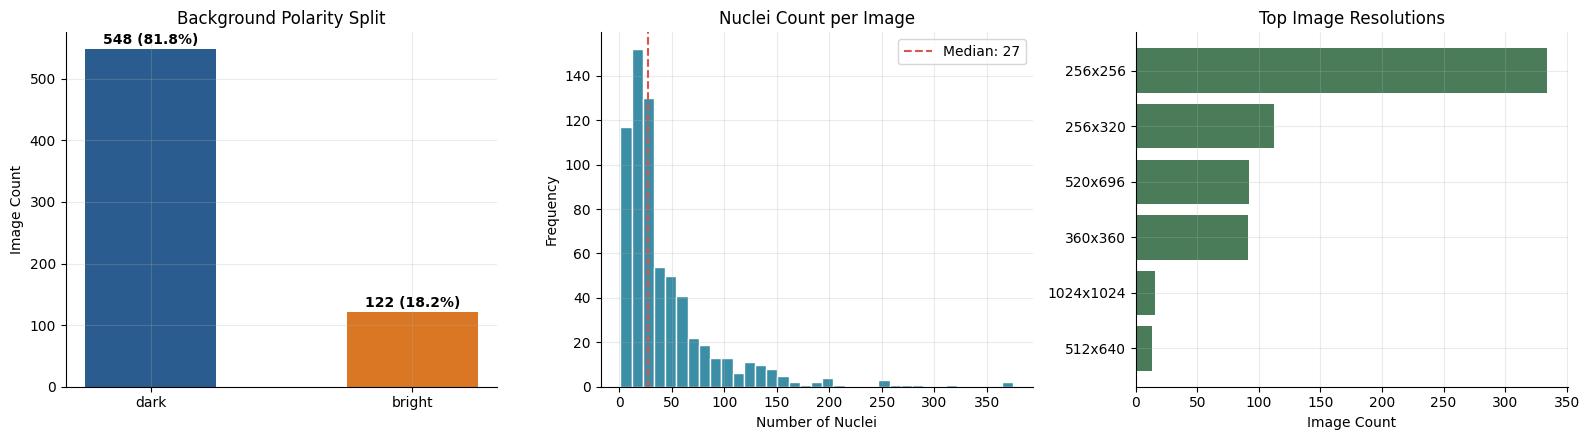

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

# 1. Background Polarity Split
bg_counts = df["bg_type"].value_counts()
axes[0].bar(bg_counts.index, bg_counts.values, color=["#2b5c8f", "#d97724"], width=0.5)
axes[0].set_title("Background Polarity Split")
axes[0].set_ylabel("Image Count")
for idx, val in enumerate(bg_counts.values):
    axes[0].text(idx, val + 8, f"{val} ({val/len(df):.1%})", ha="center", fontweight="bold")

# 2. Nuclei Count Distribution
axes[1].hist(df["n_nuclei"], bins=35, color="#3b8ea5", edgecolor="white")
axes[1].axvline(df["n_nuclei"].median(), color="#d9534f", linestyle="--",
                label=f"Median: {df['n_nuclei'].median():.0f}")
axes[1].set_title("Nuclei Count per Image")
axes[1].set_xlabel("Number of Nuclei")
axes[1].set_ylabel("Frequency")
axes[1].legend()

# 3. Top Image Resolutions
top_res = df["resolution"].value_counts().head(6)
axes[2].barh(top_res.index[::-1], top_res.values[::-1], color="#4a7c59")
axes[2].set_title("Top Image Resolutions")
axes[2].set_xlabel("Image Count")

plt.tight_layout()
plt.show()

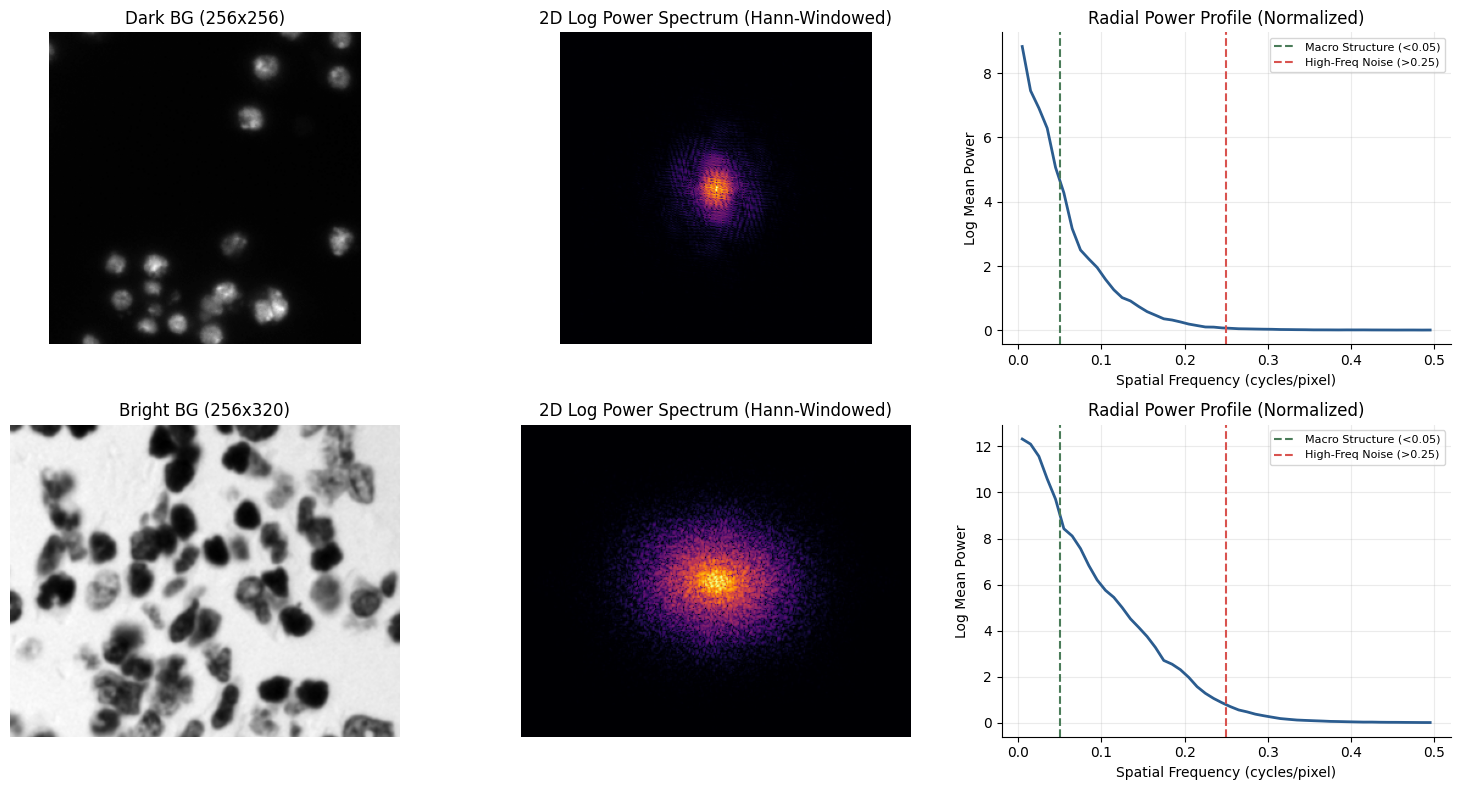

In [11]:
def compute_radial_power_spectrum(gray_float: np.ndarray):
    """Computes zero-mean, Hann-windowed 2D FFT and normalized radial power profile."""
    h, w = gray_float.shape
    centered = gray_float - gray_float.mean()
    window = np.outer(np.hanning(h), np.hanning(w))
    windowed = centered * window

    f_shift = np.fft.fftshift(np.fft.fft2(windowed))
    power_2d = np.abs(f_shift) ** 2

    # Normalized frequency coordinates in cycles/pixel [-0.5, 0.5]
    fy = np.fft.fftshift(np.fft.fftfreq(h))
    fx = np.fft.fftshift(np.fft.fftfreq(w))
    fx_grid, fy_grid = np.meshgrid(fx, fy)
    freq_radius = np.sqrt(fx_grid**2 + fy_grid**2)

    bins = np.linspace(0.0, 0.5, 51)
    bin_centers = 0.5 * (bins[:-1] + bins[1:])
    radial_profile = np.zeros(len(bin_centers))

    for i in range(len(bin_centers)):
        mask = (freq_radius >= bins[i]) & (freq_radius < bins[i + 1])
        radial_profile[i] = power_2d[mask].mean() if np.any(mask) else np.nan

    return np.log1p(power_2d), bin_centers, np.log1p(radial_profile)


sample_dark = df[df["bg_type"] == "dark"].iloc[0]["image_id"]
sample_bright = df[df["bg_type"] == "bright"].iloc[0]["image_id"]

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for row_idx, (label, img_id) in enumerate([("Dark BG", sample_dark), ("Bright BG", sample_bright)]):
    img_rgb, _, _, _ = load_image_and_masks(DATA_DIR / img_id)
    gray = color.rgb2gray(img_rgb)
    log_spec, freqs, rad_prof = compute_radial_power_spectrum(gray)

    axes[row_idx, 0].imshow(gray, cmap="gray")
    axes[row_idx, 0].set_title(f"{label} ({gray.shape[0]}x{gray.shape[1]})")
    axes[row_idx, 0].axis("off")

    axes[row_idx, 1].imshow(log_spec, cmap="inferno")
    axes[row_idx, 1].set_title("2D Log Power Spectrum (Hann-Windowed)")
    axes[row_idx, 1].axis("off")

    axes[row_idx, 2].plot(freqs, rad_prof, color="#2b5c8f", linewidth=2)
    axes[row_idx, 2].axvline(0.05, color="#4a7c59", linestyle="--", label="Macro Structure (<0.05)")
    axes[row_idx, 2].axvline(0.25, color="#d9534f", linestyle="--", label="High-Freq Noise (>0.25)")
    axes[row_idx, 2].set_title("Radial Power Profile (Normalized)")
    axes[row_idx, 2].set_xlabel("Spatial Frequency (cycles/pixel)")
    axes[row_idx, 2].set_ylabel("Log Mean Power")
    axes[row_idx, 2].legend(fontsize=8)

plt.tight_layout()
plt.show()